In [1]:
!pip install -q tensorflow-hub pillow

In [2]:
import os
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow version: 2.21.0
Libraries imported successfully!


In [6]:
uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving content.jpeg to content.jpeg
Uploaded files:
content.jpeg


In [7]:
uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving style.jpeg to style.jpeg
Uploaded files:
style.jpeg


In [9]:
def load_img(path, max_dim=512):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(
        img, channels=3, expand_animations=False
    )
    img = tf.image.convert_image_dtype(img, tf.float32)

    shape = tf.cast(tf.shape(img)[:2], tf.float32)
    scale = max_dim / tf.reduce_max(shape)
    new_shape = tf.cast(shape * scale, tf.int32)

    img = tf.image.resize(img, new_shape)
    return img[tf.newaxis, :]


content_path = "content.jpeg"
style_path = "style.jpeg"

content_image = load_img(content_path)
style_image = load_img(style_path)

print("Content image shape:", content_image.shape)
print("Style image shape:", style_image.shape)

Content image shape: (1, 288, 512, 3)
Style image shape: (1, 512, 512, 3)


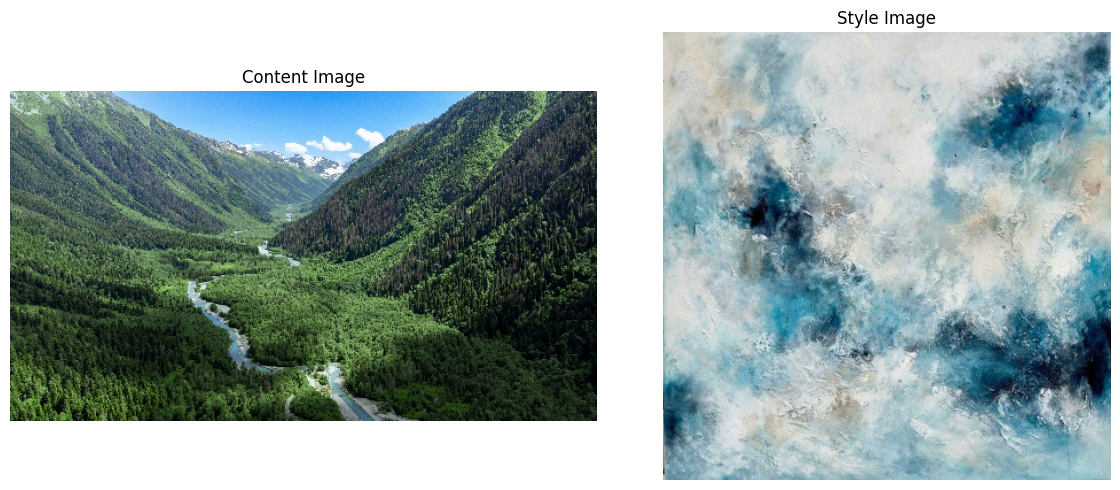

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(content_image[0])
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(style_image[0])
plt.title("Style Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
hub_model = hub.load(
    "https://tfhub.dev/google/magenta/"
    "arbitrary-image-stylization-v1-256/2"
)

print("Style-transfer model loaded successfully!")

Style-transfer model loaded successfully!


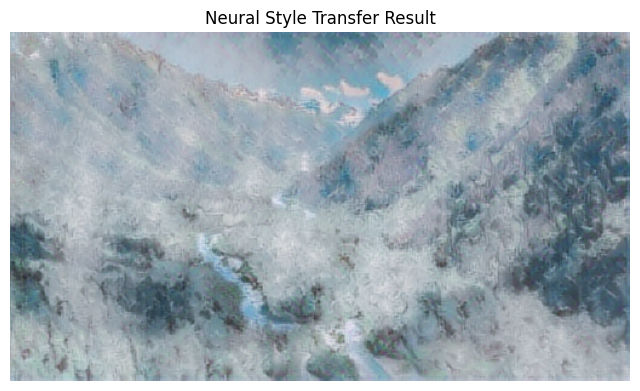

In [14]:
stylized_image = hub_model(
    tf.constant(content_image),
    tf.constant(style_image)
)[0]

plt.figure(figsize=(8, 8))
plt.imshow(tf.squeeze(stylized_image, axis=0))
plt.title("Neural Style Transfer Result")
plt.axis("off")
plt.show()